# Pós-Graduação em IA Aplicada
### Unidade Curricular: Machine Learning
**Professor:** Giancarlo Marchesini, Me.

**Aluno:** Adair José Limana

---

# Trabalho Prático: Regressão e Seleção de Modelos com o Dataset Concrete Compressive Strength

## Contexto e Dataset

A resistência à compressão do concreto é uma propriedade fundamental na engenharia civil, determinada de forma altamente não linear por variáveis de composição e tempo de cura. Neste projeto, você utilizará o dataset **Concrete Compressive Strength** do repositório UCI Machine Learning.

- **Instâncias:** 1.030 amostras
- **Atributos de entrada (8 variáveis contínuas):** Cimento, Escória de Alto Forno, Cinza Volante, Água, Superplastificante, Agregado Graúdo, Agregado Fino e Idade de Cura (dias)
- **Variável alvo (target):** resistência à compressão do concreto em MPa (megapascals)

## Objetivo do Trabalho

Desenvolver um pipeline completo de Machine Learning para regressão no Google Colab, cobrindo desde a análise exploratória e o pré-processamento até o ajuste de hiperparâmetros, a comparação de modelos e a interpretação técnica dos resultados.

## Requisitos do Notebook Colab

- Código Python bem comentado, modularizado e utilizando **pipelines do scikit-learn** sempre que possível.
- Seções organizadas com títulos em Markdown (`#`, `##`).
- Gráficos legíveis, com eixos rotulados e títulos claros.
- Respostas analíticas da Etapa 7 escritas em **células Markdown** deste próprio notebook.

# Configuração do ambiente

Rode a célula abaixo antes de começar. Acrescente aqui os demais imports de que precisar ao longo do trabalho.

In [1]:
import time
import warnings
import pandas as pd
import seaborn as sns

import numpy as np
from numpy.random.mtrand import randint

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate,
    GridSearchCV, RandomizedSearchCV,
)

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error,
)

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

# Funções Utilitárias e Constantes

In [2]:
TARGET_COLUMN = 'Concrete compressive strength'
SEED = 77

warnings.filterwarnings("ignore", category=ConvergenceWarning)

REGRESSORS_LABEL = {
    "LINEAR": "Regressão Linear",
    "KNN": "K-NN",
    "MLP": "Rede Neural (MLP)",
    "RANDOM_FOREST": "Random Forest",
    "GRADIENT_BOSTING": "Gradient Boosting",
    "SVR": "SVR",
    "ELASTICNET": "ElasticNet",
    "DECISION_TREE": "Árvore de Decisão",
    "RIDGE": "Ridge",
}

regressors = {
    REGRESSORS_LABEL["LINEAR"]: lambda: LinearRegression(),
    REGRESSORS_LABEL["KNN"]: lambda: KNeighborsRegressor(n_neighbors=5),
    REGRESSORS_LABEL["SVR"]: lambda: SVR(kernel="rbf"),
    REGRESSORS_LABEL["DECISION_TREE"]: lambda: DecisionTreeRegressor(max_depth=5, random_state=SEED),
    REGRESSORS_LABEL["RANDOM_FOREST"]: lambda: RandomForestRegressor(n_estimators=200, random_state=SEED),
    REGRESSORS_LABEL["GRADIENT_BOSTING"]: lambda: GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, random_state=SEED),
    REGRESSORS_LABEL["RIDGE"]: lambda: Ridge(alpha=1.0, random_state=SEED),
    REGRESSORS_LABEL["ELASTICNET"]: lambda: ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=SEED),
    REGRESSORS_LABEL["MLP"]: lambda: MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=SEED)
}

#Map das classes de modelos pela labels.
MODEL_CLASS_BY_LABEL = {
    REGRESSORS_LABEL["LINEAR"]: LinearRegression,
    REGRESSORS_LABEL["KNN"]: KNeighborsRegressor,
    REGRESSORS_LABEL["SVR"]: SVR,
    REGRESSORS_LABEL["DECISION_TREE"]: DecisionTreeRegressor,
    REGRESSORS_LABEL["RANDOM_FOREST"]: RandomForestRegressor,
    REGRESSORS_LABEL["GRADIENT_BOSTING"]: GradientBoostingRegressor,
    REGRESSORS_LABEL["RIDGE"]: Ridge,
    REGRESSORS_LABEL["ELASTICNET"]: ElasticNet,
    REGRESSORS_LABEL["MLP"]: MLPRegressor
}

def format_probabilities(probabilities, classes):
    """Converte um array de probabilidades em um dicionário limpo {classe: probabilidade}, pronto para imprimir."""
    return {class_: round(float(p), 3) for class_, p in zip(classes, probabilities)}

# Roteiro de Desenvolvimento (Etapas Obrigatórias)

# 1. Carregamento dos Dados e Análise Exploratória (EDA)

- Obtenha os dados via biblioteca `ucimlrepo` (`fetch_ucirepo(id=165)`) ou por download direto da URL da UCI.
- Exiba estatísticas descritivas (média, desvio padrão, quartis, mínimo e máximo) das 8 variáveis de entrada e da variável alvo.
- Plote gráficos de distribuição (histogramas/KDE) e uma matriz de correlação (heatmap) para identificar potenciais correlações lineares e multicolinearidade.

## 1.1 Carregamento dos dados

In [3]:
BASE_URL = 'https://raw.githubusercontent.com/AdaLimana/pos-ia/refs/heads/main/ma/project-02/'

df_original = pd.read_csv(BASE_URL + 'concrete.csv')

df = df_original.copy()

print('Dados carregados com sucesso!')
print(f'Registros: {df.shape[0]} registros\n')

print(f'Colunas do DF carregado: {df.columns}\n')
print(f'Possui: {df.shape[0]} linhas, {df.shape[1]} colunas.')

Dados carregados com sucesso!
Registros: 1030 registros

Colunas do DF carregado: Index(['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer',
       'Coarse Aggregate', 'Fine Aggregate', 'Age',
       'Concrete compressive strength'],
      dtype='object')

Possui: 1030 linhas, 9 colunas.


In [4]:
display(df.head())

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [5]:
print(f"REGISTROS DUPLICADOS")
qtd_linhas_antes = df.shape[0]
df = df.drop_duplicates()

qtd_linhas_removidas = qtd_linhas_antes - df.shape[0]

if qtd_linhas_removidas > 0:
  print(f'Foram removidas {qtd_linhas_removidas} registro(s) duplicado(s)\n')
else:
  print(f'Não possui valore duplicados\n')

print(f"VALORES AUSENTES")
nulos = df.isnull().sum()
colunas_com_nulos = nulos[nulos > 0]
total = df.shape[0]

if len(colunas_com_nulos):
  for col, qtd in colunas_com_nulos.items():
    print(f"'{col}': {qtd} nulos ({qtd/total:.1%})")
else:
  print("Sem valores ausentes")

REGISTROS DUPLICADOS
Foram removidas 25 registro(s) duplicado(s)

VALORES AUSENTES
Sem valores ausentes


## 1.2 Estatísticas descritivas

In [6]:
display(df.info())

print()

df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 1005 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1005 non-null   float64
 1   Blast Furnace Slag             1005 non-null   float64
 2   Fly Ash                        1005 non-null   float64
 3   Water                          1005 non-null   float64
 4   Superplasticizer               1005 non-null   float64
 5   Coarse Aggregate               1005 non-null   float64
 6   Fine Aggregate                 1005 non-null   float64
 7   Age                            1005 non-null   int64  
 8   Concrete compressive strength  1005 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 78.5 KB


None

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.631343,72.043483,55.536318,182.075323,6.033234,974.376816,772.688259,45.856716,35.250378
std,104.344261,86.170807,64.207969,21.339334,5.919967,77.579667,80.340435,63.734692,16.284815
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,190.700000,0.000000,0.000000,166.600000,0.000000,932.000000,724.300000,7.000000,23.520000
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.800000
75%,349.000000,142.500000,118.300000,192.900000,10.000000,1031.000000,822.200000,56.000000,44.870000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


## 1.3 Distribuições (histogramas/KDE)

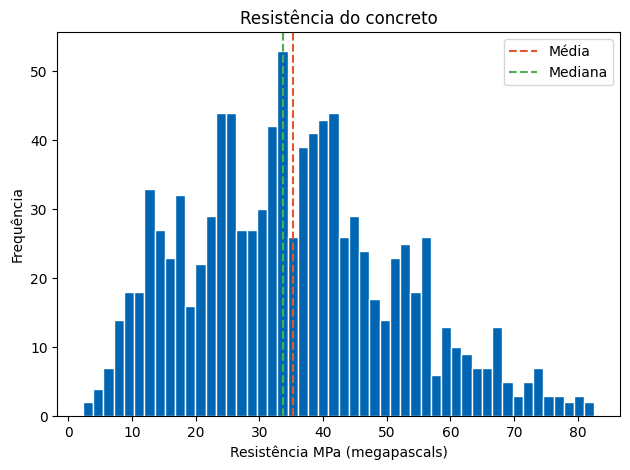

Média: 35.25 | Mediana: 33.80 | Máximo: 82.60


In [7]:
plt.hist(df[TARGET_COLUMN], bins = 50, edgecolor='white', color = '#0066B3')
plt.axvline(df[TARGET_COLUMN].mean(), color="#E4572E", linestyle="--", label="Média")
plt.axvline(df[TARGET_COLUMN].median(), color="#4CAF50", linestyle="--", label="Mediana")
plt.xlabel('Resistência MPa (megapascals)')
plt.ylabel('Frequência')
plt.title('Resistência do concreto')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Média: {df[TARGET_COLUMN].mean():.2f} | Mediana: {df[TARGET_COLUMN].median():.2f} | "
      f"Máximo: {df[TARGET_COLUMN].max():.2f}")


## 1.4 Matriz de correlação (heatmap)

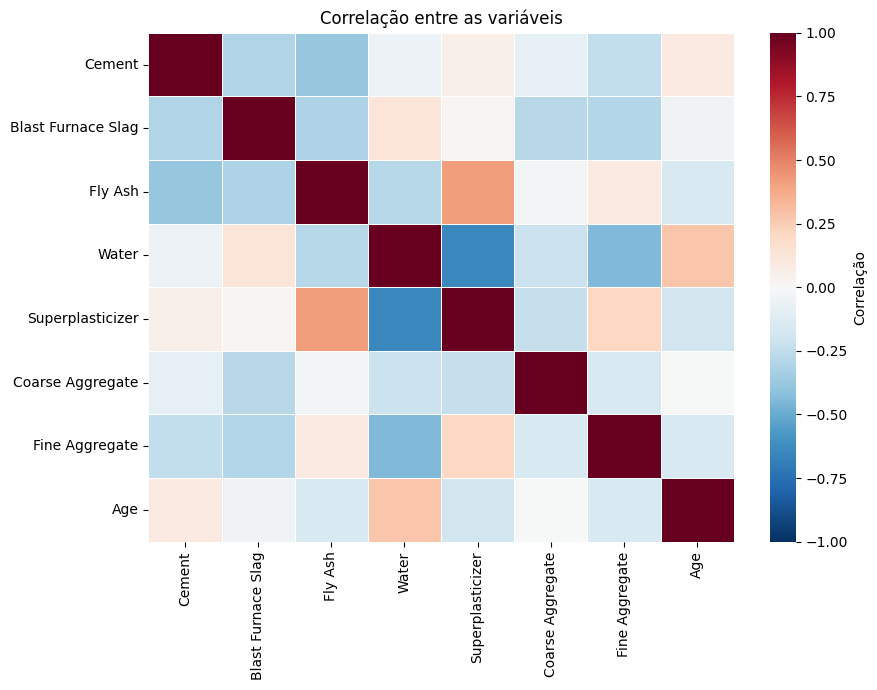

In [8]:
# Correlação entre as variáveis: ajuda a antecipar quais colunas carregam informação parecida
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns=TARGET_COLUMN).corr(), cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.4, cbar_kws={"label": "Correlação"})
plt.title("Correlação entre as variáveis")
plt.tight_layout()
plt.show()

No gráfico acima, podemos observar uma correlação negativa entre Water (água) e Superplasticizer (Aditivo químico para concreto). Essa correlação reforça o fato que o aditivo reduz a quantidade de água necessária sem que o concreto perca a rigidez.

#2. Divisão dos Dados, Pré-processamento e Validação Cruzada

- Implemente e avalie **pelo menos dois** métodos de escalonamento distintos (ex.: `StandardScaler`, `MinMaxScaler` ou `RobustScaler`).
- **Regra importante:** o ajuste (`fit`) dos escalonadores deve ser realizado **exclusivamente no conjunto de treinamento**, para evitar o vazamento de dados (*data leakage*).
- Separe os dados em conjuntos de **Treino e Teste** (ex.: proporção 80/20).
- Aplique **Validação Cruzada K-Fold** ($k=5$ ou $k=10$) no conjunto de treinamento para avaliar a estabilidade dos modelos sem viés de amostragem.

In [9]:
#Separando dados para teste e treino

X = df.drop(columns=TARGET_COLUMN)
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

print(f"Treino: {len(X_train)} amostras | Teste: {len(X_test)} amostras")

print(f"Treino: {len(X_train)} amostras | Teste: {len(X_test)} amostras")
print(f"Valor médio no treino: {y_train.mean():.2f} | Valor médio no teste: {y_test.mean():.2f}")

Treino: 703 amostras | Teste: 302 amostras
Treino: 703 amostras | Teste: 302 amostras
Valor médio no treino: 34.93 | Valor médio no teste: 35.99


In [10]:
scalers = {
    "Sem scaler": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}


cross_validation = KFold(n_splits=5, shuffle=True, random_state=SEED)

scalers_result = []
for scaler_name, scaler in scalers.items():
  for model_name, model in regressors.items():
    stages = [("modelo", model())] if scaler is None else [("escalonador", scaler), ("modelo", model())]
    pipeline = Pipeline(stages)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cross_validation,
                                    scoring="neg_mean_absolute_error")
    scalers_result.append({"scaler": scaler_name, "model": model_name, "MAE": round(-scores.mean(), 3)})

scaler_table = pd.DataFrame(scalers_result).pivot(index="scaler", columns="model", values="MAE")
scaler_table = scaler_table.reindex(scalers.keys())
scaler_table.round(4)

model,ElasticNet,Gradient Boosting,K-NN,Random Forest,Rede Neural (MLP),Regressão Linear,Ridge,SVR,Árvore de Decisão
scaler,,,,,,,,,
Sem scaler,8.294,3.874,7.725,3.910,5.175,8.294,8.294,11.369,6.339
StandardScaler,8.443,3.873,7.669,3.907,4.819,8.294,8.301,8.573,6.339
MinMaxScaler,10.135,3.870,7.880,3.902,6.204,8.294,8.382,8.972,6.328
RobustScaler,8.538,3.869,6.504,3.898,4.825,8.294,8.311,7.094,6.328


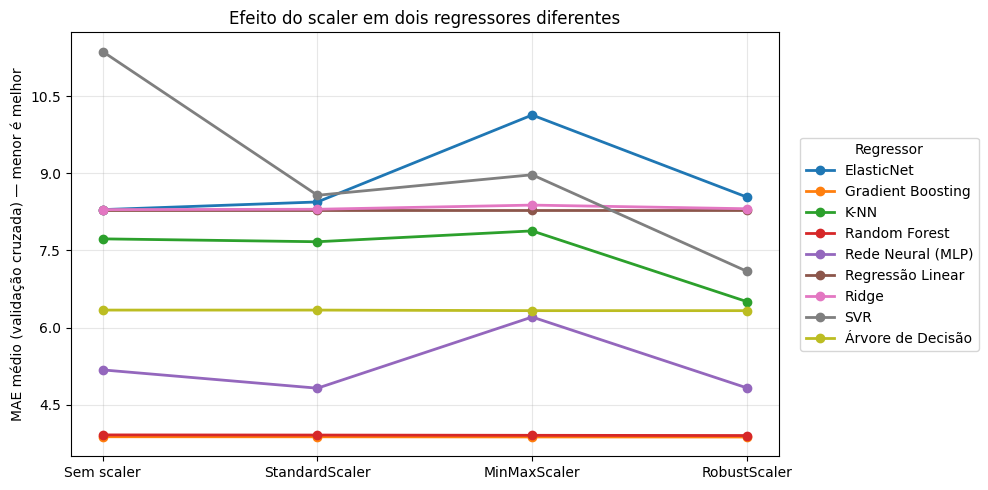

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

for model_name in scaler_table.columns:
    plt.plot(scaler_table.index, scaler_table[model_name], marker="o", linewidth=2,
             label=model_name, )
plt.ylabel("MAE médio (validação cruzada) — menor é melhor")
plt.title("Efeito do scaler em dois regressores diferentes")

ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.legend(
    title="Regressor",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=1,
    frameon=True
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Treinamento e Comparação de Múltiplos Regressores

Treine e compare no mínimo **5 modelos** de regressão, representando diferentes algoritmos:

- **Modelo linear/regularizado:** Regressão Linear Simples/Múltipla, Ridge ou Lasso.
- **Baseado em distância:** K-Nearest Neighbors Regressor ($k$-NN).
- **Baseado em margem:** Support Vector Regression (SVR).
- **Árvores de decisão / ensemble:** Random Forest Regressor.
- **Boosting:** Gradient Boosting, XGBoost ou LightGBM.

In [12]:
pipelines = { }

for name, model in regressors.items():
  pipeline = Pipeline([("escalonador", RobustScaler()), ("modelo", model())])
  pipelines[name] = pipeline

Para as seguintes análises, usaremos o RuberScaler como scaler, pois foi o que teve um menor erro médio absoluto (MAE) na seção 2.

In [13]:
regressors_result = []

cross_validation = KFold(n_splits=5, shuffle=True, random_state=SEED)

for name, model in regressors.items():
  start = time.time()
  pipeline = pipelines.get(name)
  scores = cross_val_score(pipeline, X_train, y_train, cv=cross_validation,
                                    scoring="neg_mean_absolute_error")
  end = time.time()
  regressors_result.append({"regressor": name, "MAE": round(-scores.mean(),3),
                                       "desvio": scores.std(), "tempo_gasto_treinamento (s)": (end - start)})

regressors_table = (pd.DataFrame(regressors_result)
                          .set_index("regressor").sort_values("MAE", ascending=True))

print(regressors_table.round(3))

                     MAE  desvio  tempo_gasto_treinamento (s)
regressor                                                    
Gradient Boosting  3.869   0.119                        1.367
Random Forest      3.898   0.166                        5.102
Rede Neural (MLP)  4.825   0.293                        8.841
Árvore de Decisão  6.328   0.243                        0.053
K-NN               6.504   0.257                        0.052
SVR                7.094   0.534                        0.161
Regressão Linear   8.294   0.871                        0.054
Ridge              8.311   0.877                        0.046
ElasticNet         8.538   0.861                        0.047


# 4. Métricas de Avaliação

Para **cada modelo e cada tipo de pré-processamento**, calcule as métricas abaixo no **treino**, na **validação cruzada** e no **teste final**:

- MAE (Mean Absolute Error)
- MSE (Mean Squared Error)
- RMSE (Root Mean Squared Error)
- $R^2$ (Coeficiente de Determinação)

Organize todos os resultados em uma **tabela comparativa estruturada**.

In [14]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cross_validation = KFold(n_splits=5, shuffle=True, random_state=SEED)

#Métricas coletadas em cima do TREINO, forma ERRADA de verificar a assertividade
def get_train_metrics(model):
  model.fit(X_train, y_train)
  y_train_pred = model.predict(X_train)
  mae = mean_absolute_error(y_train, y_train_pred)
  mse = mean_squared_error(y_train, y_train_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_train, y_train_pred)

  return {"mae": mae, "mse": mse, "rmse": rmse, "r2": r2}

def get_cv_metrics(model):
  cv_results = cross_validate(model, X_train, y_train, cv=cross_validation,
                               scoring=scoring)
  mae = -cv_results["test_MAE"].mean()
  mse = -cv_results["test_MSE"].mean()
  rmse = -cv_results["test_RMSE"].mean()
  r2 = cv_results["test_R2"].mean()

  return {"mae": mae, "mse": mse, "rmse": rmse, "r2": r2}

#Métricas coletadas em cima do TEST, forma CORRETA de verificar a assertividade
def get_final_test_metrics(model):
  model.fit(X_train, y_train)
  y_test_pred = model.predict(X_test)
  mae = mean_absolute_error(y_test, y_test_pred)
  mse = mean_squared_error(y_test, y_test_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_test, y_test_pred)

  return {"mae": mae, "mse": mse, "rmse": rmse, "r2": r2}

results = []

for name, model in regressors.items():
  train_metrics = get_train_metrics(model())
  cv_metrics = get_cv_metrics(model())
  final_test_metrics = get_final_test_metrics(model())
  df_metrics = pd.DataFrame([
    {
      "Modelo": name,
      "Avaliação": "Treino",
      "MAE": train_metrics['mae'],
      "MSE": train_metrics['mse'],
      "RMSE": train_metrics['rmse'],
      "R²": train_metrics['r2']
    },
    {
      "Modelo": name,
      "Avaliação": "Validação cruzada",
      "MAE": cv_metrics['mae'],
      "MSE": cv_metrics['mse'],
      "RMSE": cv_metrics['rmse'],
      "R²": cv_metrics['r2']
    },
    {
      "Modelo": name,
      "Avaliação": "Teste final",
      "MAE": final_test_metrics['mae'],
      "MSE": final_test_metrics['mse'],
      "RMSE": final_test_metrics['rmse'],
      "R²": final_test_metrics['r2']
    },
  ])
  results.append(df_metrics)

df_results = pd.concat(results, ignore_index=True)

df_results

,Modelo,Avaliação,MAE,MSE,RMSE,R²
0,Regressão Linear,Treino,8.160244,105.392132,10.266067,0.583363
1,Regressão Linear,Validação cruzada,8.294248,108.630284,10.385682,0.567031
2,Regressão Linear,Teste final,8.559519,108.297612,10.406614,0.629132
3,K-NN,Treino,5.679496,56.268102,7.501207,0.777560
4,K-NN,Validação cruzada,7.725183,102.187085,10.087915,0.593619
5,K-NN,Teste final,6.978351,88.863507,9.426744,0.695684
6,SVR,Treino,11.105646,197.580725,14.056341,0.218922
7,SVR,Validação cruzada,11.368881,205.749285,14.318615,0.180880
8,SVR,Teste final,12.360211,231.577905,15.217684,0.206955
9,Árvore de Decisão,Treino,5.352743,46.780429,6.839622,0.815067


# 5. Otimização de Hiperparâmetros (Tuning)

- Selecione os **2 melhores modelos** da etapa de comparação inicial.
- Aplique `GridSearchCV` ou `RandomizedSearchCV` com validação cruzada para encontrar a combinação ideal de hiperparâmetros.
- Documente:
  - a grade de parâmetros testada;
  - os melhores parâmetros encontrados;
  - o ganho percentual em desempenho em relação ao modelo baseline.

In [15]:
# Dicionário que vai guardar o melhor pipeline de CADA regressor, já ajustado e treinado
best_pipelines = {}
# Dicionário que guarda os hiperparâmetros vencedores de cada busca
best_hyperparameters = {}
# Lista que vai acumular uma linha de resultado por regressor, para a tabela final
final_results = []

def record_result(name, search):
    """Guarda o pipeline vencedor, seus hiperparâmetros, e compara o MAE antes/depois do ajuste."""
    best_index = search.best_index_
    best_train_time = search.cv_results_["mean_fit_time"][best_index]
    best_pipelines[name] = search.best_estimator_
    best_hyperparameters[name] = search.best_params_
    best_mae = -search.best_score_
    default_mae = regressors_table.loc[name, 'MAE']
    default_train_time = regressors_table.loc[name, 'tempo_gasto_treinamento (s)']

    final_results.append({
        "regressor": name,
        "mae_padrao": default_mae,
        "tempo_gasto_treinamento_padrao": default_train_time,
        "mae_ajustada": best_mae,
        "tempo_gasto_treinamento_ajustada": best_train_time,
    })

    ganho =  (default_mae - best_mae) / default_mae * 100
    print(f"Melhores hiperparâmetros: {search.best_params_}\n")

    print("## Métricas com parâmetros padrão")
    print(f"Erro absoluto médio: {default_mae:.3f}")
    print(f"Tempo gasto treinamento: {default_train_time:.2f}s\n")

    print("## Métricas com parâmetros ajustados")
    print(f"Erro absoluto médio:     {best_mae:.3f}")
    print(f"Tempo gasto treinamento: {best_train_time:.2f}s\n")

    print(f"Ganho de {ganho:.2f}% de desempenho em relação ao modelo padrão")

##5.1 Random Forest

In [16]:
grid_random_forest = {"modelo__n_estimators": [100, 200, 400, 800], "modelo__max_depth": [None, 3, 5, 10],
                    "modelo__max_features": ["sqrt", 0.5, None]}

search_random_forest = GridSearchCV(pipelines[REGRESSORS_LABEL["RANDOM_FOREST"]], grid_random_forest, cv=cross_validation,
                               scoring="neg_mean_absolute_error", n_jobs=-1)

search_random_forest.fit(X_train, y_train)
record_result(REGRESSORS_LABEL["RANDOM_FOREST"], search_random_forest)

Melhores hiperparâmetros: {'modelo__max_depth': None, 'modelo__max_features': None, 'modelo__n_estimators': 800}

## Métricas com parâmetros padrão
Erro absoluto médio: 3.898
Tempo gasto treinamento: 5.10s

## Métricas com parâmetros ajustados
Erro absoluto médio:     3.884
Tempo gasto treinamento: 5.65s

Ganho de 0.37% de desempenho em relação ao modelo padrão


##5.2 Gradient Boosting

In [17]:
grid_gradient_boosting = {"modelo__n_estimators": [75, 150, 300, 600], "modelo__learning_rate": [0.001, 0.01, 0.1, 0.5, 1],
                    "modelo__max_depth": [None, 3, 5, 10]}

search_gradient_boosting = GridSearchCV(pipelines[REGRESSORS_LABEL["GRADIENT_BOSTING"]], grid_gradient_boosting, cv=cross_validation,
                               scoring="neg_mean_absolute_error", n_jobs=-1)

search_gradient_boosting.fit(X_train, y_train)
record_result(REGRESSORS_LABEL["GRADIENT_BOSTING"], search_gradient_boosting)

Melhores hiperparâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 3, 'modelo__n_estimators': 600}

## Métricas com parâmetros padrão
Erro absoluto médio: 3.869
Tempo gasto treinamento: 1.37s

## Métricas com parâmetros ajustados
Erro absoluto médio:     3.330
Tempo gasto treinamento: 1.45s

Ganho de 13.94% de desempenho em relação ao modelo padrão


##5.3 Resultados após hiperparametrização

In [18]:
final_table = pd.DataFrame(final_results).set_index("regressor")
final_table["ganho"] = final_table["mae_padrao"] - final_table["mae_ajustada"]
final_table = final_table.sort_values("mae_ajustada", ascending=True)
final_table.round(4)

,mae_padrao,tempo_gasto_treinamento_padrao,mae_ajustada,tempo_gasto_treinamento_ajustada,ganho
regressor,,,,,
Gradient Boosting,3.869,1.3675,3.3298,1.4545,0.5392
Random Forest,3.898,5.1025,3.8836,5.6484,0.0144


In [19]:
FINAL_MODEL_NAME = final_table.index[0]
print(f"Modelo final, após o ajuste de hiperparâmetros: {FINAL_MODEL_NAME}")
print(f"Erro Absoluto Médio (MAE): {final_table.loc[FINAL_MODEL_NAME, 'mae_ajustada']:.3f}")

Modelo final, após o ajuste de hiperparâmetros: Gradient Boosting
Erro Absoluto Médio (MAE): 3.330


# 6. Análise e Interpretação dos Resultados

Responda analiticamente às perguntas abaixo, **em células Markdown** neste notebook. Apoie cada resposta nos números e gráficos das etapas anteriores.

## 6.1 Sensibilidade aos Scalers

Quais modelos tiveram seu desempenho fortemente alterado pela escolha do scaler e quais foram insensíveis? Explique a razão teórica (ex.: modelos baseados em distância/gradiente vs. modelos baseados em árvores).

✍️ **Sua resposta:**

Os modelos SVR, K-NN, ElasticNet e Rede Neural (MLP) se mostraram sensíveis ao uso dos scalers. Desses modelos, o SVR e o K-NN apresentaram melhorias significativas, com ganhos, a partir do uso do RobustScaler, de 37,60% e 15,80%, respectivamente, na redução do **Erro Absoluto Médio** (MAE).

Já os modelos ElasticNet e Rede Neural (MLP), embora também tenham se mostrado sensíveis, apresentaram uma **piora** de 22,20% e 19,88%, respectivamente, com o uso do MinMaxScaler. A Rede Neural (MLP) apresentou ganhos inferiores a 7% com o uso do StandardScaler, enquanto o ElasticNet não apresentou nenhuma melhora.

Os demais modelos, Gradient Boosting, Random Forest, Regressão Linear, Ridge e Árvore de Decisão não tiveram mudança significativa, mantendo o Erro Absoluto Médio igual ou aproximadamente igual.

Os resultados são coerentes com as características dos algoritmos, pois modelos como SVR e K-NN dependem de medidas de distância, ficando sensíveis à escala das variáveis. Por outro lado, modelos baseados em árvores, como Random Forest, Gradient Boosting e Árvore de Decisão, separam os dados de acordo com os valores das variáveis e tendem a ser pouco afetados por transformações de escala.

## 6.2 Overfitting vs. Underfitting

Algum dos modelos apresentou sinais claros de overfitting (alto desempenho no treino, mas queda na validação/teste)? Como o tuning de hiperparâmetros ajudou a mitigar esse efeito?

✍️ **Sua resposta:**

Sim Random Forest e Gradient Boosting apresentaram Overfitting.

O Random Forest apresentou MAE de 1,42 no treinamento e 3,76 no teste, um aumento de 2,34 pontos (164,79%) no erro. Já o Gradient Boosting apresentou MAE de 2,32 no treinamento e 3,62 no teste, um aumento de 1,30 pontos (66,81%) no erro.

Com o uso da hiperparâmetrização, o Random Forest teve uma diminuição de 0,014 pontos (0,34%) no erro. Já o Gradient Boosting teve uma diminuição de 0,539 pontos (13,93%) no erro.

## 6.3 Importância de Atributos (Feature Importance)

Quais foram as **3 variáveis mais influentes** para a previsão da resistência do concreto no melhor modelo selecionado? Apresente um gráfico com essa relevância.

Age       0.350955
Cement    0.301073
Water     0.144699
dtype: float64



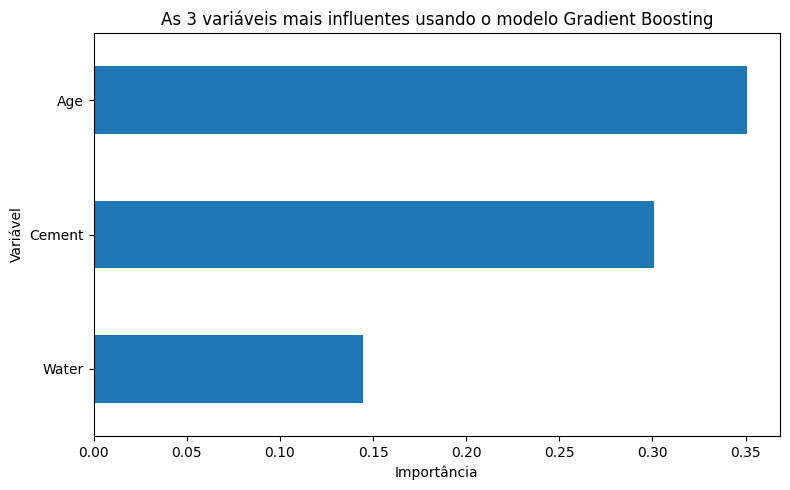

In [20]:
model = best_pipelines[FINAL_MODEL_NAME].named_steps["modelo"]

importancias = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

top_3 = importancias.head(3)

print(top_3)
print()

plt.figure(figsize=(8, 5))
top_3.sort_values().plot(kind="barh")

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title(f"As 3 variáveis mais influentes usando o modelo {FINAL_MODEL_NAME}")

plt.tight_layout()
plt.show()

## 6.4 Interpretação de Negócio/Engenharia

Analisando o erro absoluto médio (MAE) na unidade original (MPa), o desempenho do modelo é aceitável para estimar a resistência do concreto na prática? Justifique sua resposta.

✍️ **Sua resposta:**

O modelo apresentou um MAE de **3,30 MPa**, indicando que as previsões diferem, em média, 3,30 MPa dos valores reais de resistência do concreto. Esse erro corresponde a aproximadamente **9,36%** da resistência média do conjunto de dados, onde a média é de **35,25 MPa**.

Levendo isso em consideração, podemos dizer que um erro médio de 3,30 MPa é relativamente pequeno quando comparado à própria média de 35,25 MPa.

# Referência

Yeh, I.-C. (1998). *Concrete Compressive Strength* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PK67 (Licença CC BY 4.0)